# Lab 1 — Reconstruct a Synthetic Patient’s Data Journey
**AI in Healthcare · Data ecosystem**

**Student:** Jasneet Kaur  
**Notebook:** `lab-01-data-ecosystem.ipynb`

> All records in this notebook are synthetic teaching examples. They are not clinical evidence and must not be used to evaluate model performance, disease prevalence, or clinical usefulness.

## Approach
This notebook completes the inventory, data dictionary, quality audit, record linkage, cohort definition, FHIR comparison, visualizations, and reflection. Explanations are written alongside reproducible code. Run the cells from top to bottom.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("healthcare_ecosystem_lab_data")
DATA.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

## 0. Create the synthetic teaching files

The following generator reproduces the fixture described in the lab handout: patients, encounters, observations, notes, wearable samples, and a small R4-style FHIR collection Bundle. The deliberate duplicate, missing observation value, mixed temperature units, and wearable gap are retained so they can be audited.

In [2]:
patients = pd.DataFrame([
    ("P001", 1980), ("P002", 1992), ("P003", 1975), ("P004", 2000)
], columns=["patient_id", "birth_year"])

encounters = pd.DataFrame([
    ("E001", "P001", "2026-01-10T09:00:00+05:30", "outpatient"),
    ("E002", "P001", "2026-02-10T10:00:00+05:30", "outpatient"),
    ("E003", "P002", "2026-01-15T11:00:00+05:30", "outpatient"),
    ("E004", "P003", "2026-01-20T09:00:00+05:30", "outpatient"),
    ("E005", "P003", "2026-03-01T09:00:00+05:30", "outpatient"),
    ("E006", "P004", "2025-12-20T09:00:00+05:30", "outpatient")
], columns=["encounter_id", "patient_id", "start", "type"])

observations = pd.DataFrame([
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O001", "E001", "heart_rate", 78, "beats/min", "2026-01-10T09:10:00+05:30"),
    ("O002", "E001", "temperature", 37, "Cel", "2026-01-10T09:12:00+05:30"),
    ("O003", "E002", "heart_rate", None, "beats/min", "2026-02-10T10:10:00+05:30"),
    ("O004", "E003", "temperature", 98.6, "[degF]", "2026-01-15T11:10:00+05:30"),
    ("O005", "E004", "heart_rate", 84, "beats/min", "2026-01-20T09:10:00+05:30"),
    ("O006", "E005", "heart_rate", 80, "beats/min", "2026-03-01T09:10:00+05:30")
], columns=["observation_id", "encounter_id", "code", "value", "unit", "effective_time"])

notes = pd.DataFrame([
    ("N001", "P001", "E001", "No history of diabetes. Patient reports reduced activity."),
    ("N002", "P001", "E002", "Follow-up visit. Further assessment planned."),
    ("N003", "P002", "E003", "Family history of diabetes; patient history not established.")
], columns=["note_id", "patient_id", "encounter_id", "text"])

times = pd.date_range("2026-01-10T00:00:00+05:30", periods=24, freq="h")
wearable = pd.DataFrame({
    "patient_id": "P001", "time": times,
    "steps": [0,0,0,0,0,20,100,250,300,150,80,120,
              200,180,90,140,220,400,350,200,100,40,10,0]
})
# Six expected hourly samples are deliberately absent. A gap is not a zero.
wearable = wearable.drop(index=range(12,18)).reset_index(drop=True)

for name, frame in {
    "patients": patients, "encounters": encounters, "observations": observations,
    "notes": notes, "wearable": wearable
}.items():
    frame.to_csv(DATA / f"{name}.csv", index=False)

resources = [{"resourceType":"Patient", "id":p} for p in patients.patient_id]
for row in encounters.itertuples():
    resources.append({
        "resourceType":"Encounter", "id":row.encounter_id, "status":"finished",
        "class":{"system":"http://terminology.hl7.org/CodeSystem/v3-ActCode", "code":"AMB"},
        "subject":{"reference":f"Patient/{row.patient_id}"},
        "period":{"start":row.start}
    })
for oid, pid, eid, value, time in [
    ("O001","P001","E001",78,"2026-01-10T09:10:00+05:30"),
    ("O005","P003","E004",84,"2026-01-20T09:10:00+05:30")
]:
    resources.append({
        "resourceType":"Observation", "id":oid, "status":"final",
        "code":{"coding":[{"system":"http://loinc.org", "code":"8867-4", "display":"Heart rate"}]},
        "subject":{"reference":f"Patient/{pid}"},
        "encounter":{"reference":f"Encounter/{eid}"},
        "effectiveDateTime":time,
        "valueQuantity":{"value":value, "unit":"beats/minute",
                         "system":"http://unitsofmeasure.org", "code":"/min"}
    })

bundle = {"resourceType":"Bundle", "type":"collection", "entry":[
    {"fullUrl":f"https://example.org/fhir/{r['resourceType']}/{r['id']}", "resource":r}
    for r in resources
]}
(DATA / "patient_bundle.json").write_text(json.dumps(bundle, indent=2), encoding="utf-8")
print("Created five CSV files and one JSON Bundle in:", DATA.resolve())

Created five CSV files and one JSON Bundle in: /content/healthcare_ecosystem_lab_data


## 1. Inventory

### Student response

| File | Meaning of one row | Identifier(s) | Representation | Potential use |
|---|---|---|---|---|
| `patients.csv` | One synthetic person and their birth year | `patient_id` | Structured CSV table | Link a person to their encounters and observations |
| `encounters.csv` | One visit/encounter for a patient, with a start time and type | `encounter_id`; `patient_id` is a foreign key | Structured CSV table with timestamp | Define visit-level cohorts and attach clinical events to visits |
| `observations.csv` | One recorded measurement/event associated with an encounter | `observation_id`; `encounter_id` is a foreign key | Structured CSV table; value and unit are separate fields | Analyze recorded measurements after checking duplicates, missingness, and units |
| `notes.csv` | One clinical note associated with a patient and encounter | `note_id`; `patient_id` and `encounter_id` are references | Structured columns containing unstructured free-text note content | Review narrative context and link it to the correct visit |
| `wearable.csv` | One hourly wearable step-count sample for a patient | Composite practical key: `patient_id` + `time` | Time-series CSV table | Examine activity patterns and missing sampling intervals |

These files are **both sources and representations** in the context of this exercise: each is a supplied source table, and CSV is its tabular representation. The notes file still contains unstructured text because the `text` field is free prose rather than a set of standardized coded fields. The surrounding note identifiers and references are structured, but the narrative itself is not.

Lecture-source categories not represented as separate files in this fixture include imaging, laboratory-system source records beyond the simplified observation table, medication/order records, claims/billing, and other external or device systems. The fixture does include a small wearable stream, but it does not represent a complete real-world data ecosystem.

In [3]:
tables = {
    name: pd.read_csv(DATA / f"{name}.csv")
    for name in ["patients", "encounters", "observations", "notes", "wearable"]
}
for name, frame in tables.items():
    print(f"{name}: {frame.shape}")
    display(frame.head(3))

patients, encounters, observations, notes, wearable = [tables[n] for n in tables]
encounters["start"] = pd.to_datetime(encounters["start"], utc=True)
observations["effective_time"] = pd.to_datetime(observations["effective_time"], utc=True)
wearable["time"] = pd.to_datetime(wearable["time"], utc=True)

patients: (4, 2)


,patient_id,birth_year
0,P001,1980
1,P002,1992
2,P003,1975


encounters: (6, 4)


,encounter_id,patient_id,start,type
0,E001,P001,2026-01-10T09:00:00+05:30,outpatient
1,E002,P001,2026-02-10T10:00:00+05:30,outpatient
2,E003,P002,2026-01-15T11:00:00+05:30,outpatient


observations: (7, 6)


,observation_id,encounter_id,code,value,unit,effective_time
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
1,O001,E001,heart_rate,78.0,beats/min,2026-01-10T09:10:00+05:30
2,O002,E001,temperature,37.0,Cel,2026-01-10T09:12:00+05:30


notes: (3, 4)


,note_id,patient_id,encounter_id,text
0,N001,P001,E001,No history of diabetes. Patient reports reduced activity.
1,N002,P001,E002,Follow-up visit. Further assessment planned.
2,N003,P002,E003,Family history of diabetes; patient history not established.


wearable: (18, 3)


,patient_id,time,steps
0,P001,2026-01-10 00:00:00+05:30,0
1,P001,2026-01-10 01:00:00+05:30,0
2,P001,2026-01-10 02:00:00+05:30,0


## 2. Data dictionary and quality audit

The dictionary below has 14 entries across the five supplied files. The key role distinguishes primary identifiers from foreign references and non-key attributes. “Not applicable” is used where a unit does not apply; missingness is described from the meaning of the field rather than treating every blank as interchangeable.

In [4]:
dictionary_rows = [
    ("patients.csv","patient_id","Synthetic person identifier","string","Not applicable","Primary key","Should not be missing; missing ID prevents person-level linkage"),
    ("patients.csv","birth_year","Year of birth","integer","year","Attribute","Missing means age cannot be derived from this field"),
    ("encounters.csv","encounter_id","Unique synthetic visit identifier","string","Not applicable","Primary key","Should not be missing; missing ID prevents visit-level linkage"),
    ("encounters.csv","patient_id","Person associated with the encounter","string","Not applicable","Foreign key to patients.patient_id","Missing means the encounter cannot be assigned to a person"),
    ("encounters.csv","start","Encounter start timestamp","datetime with timezone","timestamp","Time attribute","Missing means visit timing and time-window eligibility cannot be determined"),
    ("encounters.csv","type","Encounter category","string","Not applicable","Attribute","Missing means encounter category is unknown"),
    ("observations.csv","observation_id","Identifier for an observation record","string","Not applicable","Identifier; expected unique in this fixture after exact duplicate removal","Missing means the observation cannot be reliably identified"),
    ("observations.csv","encounter_id","Visit associated with the observation","string","Not applicable","Foreign key to encounters.encounter_id","Missing means visit linkage is unavailable"),
    ("observations.csv","code","Type of measurement, e.g. heart_rate","string","Not applicable","Measurement concept attribute","Missing means the measurement concept is unknown"),
    ("observations.csv","value","Numeric measurement value","float","Depends on unit column","Measurement value","Missing means the measurement was recorded as an event but its numeric result is unavailable"),
    ("observations.csv","unit","Unit attached to the measurement value","string","e.g. beats/min, Cel, [degF]","Measurement metadata","Missing means the numeric value cannot be safely interpreted"),
    ("observations.csv","effective_time","Time the measurement was effective/recorded in this fixture","datetime with timezone","timestamp","Event-time attribute","Missing means temporal ordering and availability analysis are limited"),
    ("notes.csv","note_id","Unique note identifier","string","Not applicable","Primary key","Missing means the note cannot be individually referenced"),
    ("notes.csv","text","Narrative note content","string","Not applicable","Unstructured content attribute","Missing means narrative context is unavailable")
]
data_dictionary = pd.DataFrame(dictionary_rows, columns=[
    "file","column","meaning","type","unit","key_role","missing_meaning"
])
display(data_dictionary)
assert len(data_dictionary) == 14
assert data_dictionary.groupby("file")["column"].count().sum() >= 8

,file,column,meaning,type,unit,key_role,missing_meaning
0,patients.csv,patient_id,Synthetic person identifier,string,Not applicable,Primary key,Should not be missing; missing ID prevents person-level linkage
1,patients.csv,birth_year,Year of birth,integer,year,Attribute,Missing means age cannot be derived from this field
2,encounters.csv,encounter_id,Unique synthetic visit identifier,string,Not applicable,Primary key,Should not be missing; missing ID prevents visit-level linkage
3,encounters.csv,patient_id,Person associated with the encounter,string,Not applicable,Foreign key to patients.patient_id,Missing means the encounter cannot be assigned to a person
4,encounters.csv,start,Encounter start timestamp,datetime with timezone,timestamp,Time attribute,Missing means visit timing and time-window eligibility cannot be determined
5,encounters.csv,type,Encounter category,string,Not applicable,Attribute,Missing means encounter category is unknown
6,observations.csv,observation_id,Identifier for an observation record,string,Not applicable,Identifier; expected unique in this fixture after exact duplicate removal,Missing means the observation cannot be reliably identified
7,observations.csv,encounter_id,Visit associated with the observation,string,Not applicable,Foreign key to encounters.encounter_id,Missing means visit linkage is unavailable
8,observations.csv,code,"Type of measurement, e.g. heart_rate",string,Not applicable,Measurement concept attribute,Missing means the measurement concept is unknown
9,observations.csv,value,Numeric measurement value,float,Depends on unit column,Measurement value,Missing means the measurement was recorded as an event but its numeric result is unavailable


In [5]:
print("Exact duplicate observation rows:", observations.duplicated().sum())
print("Repeated observation IDs:", observations.observation_id.duplicated().sum())
display(observations.isna().sum().rename("missing_count").to_frame())
display(observations.groupby(["code", "unit"], dropna=False).size().rename("rows").reset_index())
display(notes.assign(keyword_diabetes=notes.text.str.contains("diabetes", case=False, na=False)))

Exact duplicate observation rows: 1
Repeated observation IDs: 1


,missing_count
observation_id,0
encounter_id,0
code,0
value,1
unit,0
effective_time,0


,code,unit,rows
0,heart_rate,beats/min,5
1,temperature,Cel,1
2,temperature,[degF],1


,note_id,patient_id,encounter_id,text,keyword_diabetes
0,N001,P001,E001,No history of diabetes. Patient reports reduced activity.,True
1,N002,P001,E002,Follow-up visit. Further assessment planned.,False
2,N003,P002,E003,Family history of diabetes; patient history not established.,True


### Student response — four quality issues and interpretation

1. **Exact duplicate export row:** `O001` appears twice with the same encounter, code, value, unit, and effective timestamp. The exact-row duplicate count is one. For the guided analysis, one copy can be removed because every field in the two rows is identical and the teaching fixture explicitly describes this as a duplicated export row.
2. **Missing measurement value:** `O003` has a heart-rate observation record and an effective timestamp, but its numeric `value` is missing. It must remain missing; replacing it with zero would falsely imply a measured heart rate of zero.
3. **Mixed temperature units:** the temperature rows use `Cel` and `[degF]`. Values cannot be compared directly until converted to a common unit. The conversion should be performed in a copy while retaining the original `value` and `unit` so the transformation remains auditable.
4. **Keyword matching and clinical meaning:** the word “diabetes” appears in both “No history of diabetes” and “Family history of diabetes; patient history not established.” A simple keyword flag would mark both notes as positive even though one explicitly negates a personal history and the other describes family history rather than an established patient diagnosis. Keyword matching ignores negation, subject, temporality, and uncertainty.

**Duplicate-removal argument:** a repeated identifier by itself is not enough evidence to delete a record. Here, the two `O001` rows are exact duplicates across all columns, and the generator states that one identical export row was deliberately duplicated. That supports removing one copy for this exercise. If rows sharing an ID had different values, units, encounters, or timestamps, they could represent a correction, a distinct version, or a data-quality conflict and would need investigation rather than automatic deletion.

In [6]:
# Remove only fully identical rows; preserve the original observations DataFrame.
clean_obs = observations.drop_duplicates().copy()

# Convert temperature values in a copy and preserve original value and unit.
temperature_copy = clean_obs.loc[clean_obs["code"].eq("temperature")].copy()
assert temperature_copy["unit"].isin(["Cel", "[degF]"]).all()
temperature_copy["value_celsius"] = temperature_copy.apply(
    lambda row: (row["value"] - 32) * 5 / 9
    if row["unit"] == "[degF]" else row["value"],
    axis=1
)
display(temperature_copy[[
    "observation_id", "value", "unit", "value_celsius", "effective_time"
]])

assert len(observations) == 7
assert len(clean_obs) == 6
assert clean_obs["observation_id"].is_unique
assert temperature_copy["value"].tolist() == [37.0, 98.6]
assert abs(temperature_copy["value_celsius"].iloc[0] - 37.0) < 1e-9
assert abs(temperature_copy["value_celsius"].iloc[1] - 37.0) < 1e-9
print("Exact duplicate removed; source temperature values and units retained.")

,observation_id,value,unit,value_celsius,effective_time
2,O002,37.0,Cel,37.0,2026-01-10 03:42:00+00:00
4,O004,98.6,[degF],37.0,2026-01-15 05:40:00+00:00


Exact duplicate removed; source temperature values and units retained.


## 3. Link records without changing their meaning

First link encounters to patients, then observations to encounters. The `many_to_one` validation checks that each encounter maps to at most one patient row and each observation maps to at most one encounter row. The merge indicator separately checks whether references actually matched.

In [7]:
encounter_patient = encounters.merge(
    patients, on="patient_id", how="left",
    validate="many_to_one", indicator=True
)
assert encounter_patient["_merge"].eq("both").all()
encounter_patient = encounter_patient.drop(columns="_merge")

linked = clean_obs.merge(
    encounter_patient, on="encounter_id", how="left",
    validate="many_to_one", indicator=True
)
assert linked["_merge"].eq("both").all()
assert len(linked) == len(clean_obs)
linked = linked.drop(columns="_merge")
display(linked)
print("Linked rows:", len(linked))
print("Distinct patients represented in linked:", linked["patient_id"].nunique())
print("Distinct encounters represented in linked:", linked["encounter_id"].nunique())

,observation_id,encounter_id,code,value,unit,effective_time,patient_id,start,type,birth_year
0,O001,E001,heart_rate,78.0,beats/min,2026-01-10 03:40:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
1,O002,E001,temperature,37.0,Cel,2026-01-10 03:42:00+00:00,P001,2026-01-10 03:30:00+00:00,outpatient,1980
2,O003,E002,heart_rate,NaN,beats/min,2026-02-10 04:40:00+00:00,P001,2026-02-10 04:30:00+00:00,outpatient,1980
3,O004,E003,temperature,98.6,[degF],2026-01-15 05:40:00+00:00,P002,2026-01-15 05:30:00+00:00,outpatient,1992
4,O005,E004,heart_rate,84.0,beats/min,2026-01-20 03:40:00+00:00,P003,2026-01-20 03:30:00+00:00,outpatient,1975
5,O006,E005,heart_rate,80.0,beats/min,2026-03-01 03:40:00+00:00,P003,2026-03-01 03:30:00+00:00,outpatient,1975


Linked rows: 6
Distinct patients represented in linked: 3
Distinct encounters represented in linked: 5


In [8]:
# Correct note join: attach each note to its encounter.
correct_notes = encounters.merge(
    notes[["encounter_id", "note_id", "patient_id", "text"]],
    on="encounter_id", how="left",
    validate="one_to_many", indicator=True,
    suffixes=("_encounter", "_note")
)
matched_notes = correct_notes.loc[correct_notes["_merge"].eq("both")].copy()
assert (matched_notes["patient_id_encounter"] == matched_notes["patient_id_note"]).all()
print("Note join rows:", len(correct_notes))
print("Matched note rows:", len(matched_notes))
display(correct_notes[[
    "encounter_id", "patient_id_encounter", "note_id", "patient_id_note", "text", "_merge"
]])

# Demonstrate the incorrect patient-only join.
bad_join = encounters.merge(notes[["patient_id", "note_id"]], on="patient_id", how="left")
display(bad_join.loc[bad_join.patient_id.eq("P001"),
                     ["patient_id", "encounter_id", "note_id"]])
print("P001 rows after patient-only join:", len(bad_join.loc[bad_join.patient_id.eq("P001")]))

Note join rows: 6
Matched note rows: 3


,encounter_id,patient_id_encounter,note_id,patient_id_note,text,_merge
0,E001,P001,N001,P001,No history of diabetes. Patient reports reduced activity.,both
1,E002,P001,N002,P001,Follow-up visit. Further assessment planned.,both
2,E003,P002,N003,P002,Family history of diabetes; patient history not established.,both
3,E004,P003,NaN,NaN,NaN,left_only
4,E005,P003,NaN,NaN,NaN,left_only
5,E006,P004,NaN,NaN,NaN,left_only


,patient_id,encounter_id,note_id
0,P001,E001,N001
1,P001,E001,N002
2,P001,E002,N001
3,P001,E002,N002


P001 rows after patient-only join: 4


### Student response — linkage interpretation

One row of `linked` represents **one deduplicated observation record attached to its encounter and then to the patient who had that encounter**. It is observation-level, not one row per patient or one row per visit. There are six linked observations and three distinct patients.

The patient table contains four people, but `P004` does not appear in `linked` because P004 has an encounter (`E006`) but no observation in the supplied observation table. An inner-style observation-to-encounter linkage cannot create an observation that was never recorded. To retain patients without observations, start from the patient table and use left joins to encounters and then observations, keeping unmatched rows and documenting that the resulting table has a different row meaning and may contain null encounter/observation fields.

The correct note linkage uses `encounter_id`. A row of the correct join attaches a note to the visit identified by that encounter. The patient-only demonstration join is wrong because P001 has two encounters and two notes: joining only on `patient_id` pairs each of the two visits with both notes, producing four combinations. That can attach a follow-up note to the wrong visit. The explicit patient-consistency check verifies that the patient on the note agrees with the patient on the encounter. `one_to_many` is appropriate because one encounter can have multiple notes, while each note row is expected to reference one encounter.

## 4. Define a reproducible cohort

The rule is: include patients with at least two distinct encounters starting in the half-open interval **[1 January 2026, 1 March 2026)** in Asia/Kolkata local time. The start is included and the end is excluded. Count distinct encounters, not observation rows.

In [9]:
window_start = pd.Timestamp("2026-01-01", tz="Asia/Kolkata").tz_convert("UTC")
window_end = pd.Timestamp("2026-03-01", tz="Asia/Kolkata").tz_convert("UTC")

eligible_encounters = encounters.loc[
    encounters["start"].ge(window_start) &
    encounters["start"].lt(window_end)
].copy()

counts_per_patient = (
    eligible_encounters.groupby("patient_id")["encounter_id"]
    .nunique()
    .rename("encounter_count")
    .reset_index()
)
cohort = counts_per_patient.loc[counts_per_patient["encounter_count"].ge(2)].copy()

display(eligible_encounters[["encounter_id", "patient_id", "start"]])
display(counts_per_patient)
display(cohort)

assert cohort["patient_id"].tolist() == ["P001"]
assert cohort["encounter_count"].tolist() == [2]

,encounter_id,patient_id,start
0,E001,P001,2026-01-10 03:30:00+00:00
1,E002,P001,2026-02-10 04:30:00+00:00
2,E003,P002,2026-01-15 05:30:00+00:00
3,E004,P003,2026-01-20 03:30:00+00:00


,patient_id,encounter_count
0,P001,2
1,P002,1
2,P003,1


,patient_id,encounter_count
0,P001,2


### Student response — cohort result

The cohort contains **P001**, with **two distinct encounters** in the specified interval (`E001` and `E002`). P003 has one encounter inside the interval (`E004` on 20 January) and another at **1 March 2026, 09:00 Asia/Kolkata** (`E005`). The 1 March encounter is exactly at the exclusive end boundary, so it is not counted. P003 therefore has only one eligible encounter and does not meet the minimum of two.

Counting rows after joining observations would not be a reliable visit count: one encounter can have several observations, and duplicate observation exports can further inflate the row count. The correct unit is the distinct `encounter_id`. This is a record-availability cohort defined by dates and encounter counts. It does not establish disease status, disease risk, representativeness, or a causal relationship.

## 5. Read and compare the FHIR JSON

The Bundle is a small teaching subset. The following extraction reads the `subject` and `encounter` references, LOINC coding, and UCUM quantity code. It also checks that the referenced Encounter points to the same Patient as the Observation. Parsing JSON does not constitute formal FHIR/profile validation.

In [10]:
bundle_loaded = json.loads((DATA / "patient_bundle.json").read_text(encoding="utf-8"))
resource_index = {
    f"{entry['resource']['resourceType']}/{entry['resource']['id']}": entry["resource"]
    for entry in bundle_loaded["entry"]
}

fhir_rows = []
for resource in resource_index.values():
    if resource["resourceType"] != "Observation":
        continue
    patient_ref = resource["subject"]["reference"]
    encounter_ref = resource["encounter"]["reference"]
    assert patient_ref in resource_index
    assert encounter_ref in resource_index
    assert resource_index[encounter_ref]["subject"]["reference"] == patient_ref

    loinc = next(
        coding for coding in resource["code"]["coding"]
        if coding["system"] == "http://loinc.org"
    )
    quantity = resource["valueQuantity"]
    fhir_rows.append({
        "observation_id": resource["id"],
        "patient_id": patient_ref.split("/")[-1],
        "encounter_id": encounter_ref.split("/")[-1],
        "loinc_system": loinc["system"],
        "loinc_code": loinc["code"],
        "loinc_display": loinc.get("display"),
        "value": quantity["value"],
        "unit_display": quantity.get("unit"),
        "ucum_system": quantity.get("system"),
        "ucum_code": quantity.get("code"),
        "effective_time": resource["effectiveDateTime"]
    })

fhir_frame = pd.DataFrame(fhir_rows)
fhir_frame["effective_time"] = pd.to_datetime(fhir_frame["effective_time"], utc=True)
display(fhir_frame)

,observation_id,patient_id,encounter_id,loinc_system,loinc_code,loinc_display,value,unit_display,ucum_system,ucum_code,effective_time
0,O001,P001,E001,http://loinc.org,8867-4,Heart rate,78,beats/minute,http://unitsofmeasure.org,/min,2026-01-10 03:40:00+00:00
1,O005,P003,E004,http://loinc.org,8867-4,Heart rate,84,beats/minute,http://unitsofmeasure.org,/min,2026-01-20 03:40:00+00:00


### FHIR path table

| Meaning | JSON path | Example in this fixture |
|---|---|---|
| Patient reference | `Observation.subject.reference` | `Patient/P001` |
| Encounter reference | `Observation.encounter.reference` | `Encounter/E001` |
| Coding system | `Observation.code.coding[].system` | `http://loinc.org` |
| Coded observation concept | `Observation.code.coding[].code` | `8867-4` |
| Human-readable concept label | `Observation.code.coding[].display` | `Heart rate` |
| Quantity numeric value | `Observation.valueQuantity.value` | `78` |
| Unit display label | `Observation.valueQuantity.unit` | `beats/minute` |
| Unit system | `Observation.valueQuantity.system` | `http://unitsofmeasure.org` |
| Coded unit | `Observation.valueQuantity.code` | `/min` |
| Effective time | `Observation.effectiveDateTime` | Timestamp string |

### Student response — FHIR interpretation

The patient reference is at `subject.reference`, and the encounter reference is at `encounter.reference`. The observation concept is represented in `code.coding`, where `system` identifies the coding system (LOINC in this fixture) and `code` identifies the coded concept. The quantity is represented in `valueQuantity`, including its numeric `value`, display `unit`, unit `system`, and coded `code`.

The comparison uses coded units rather than display labels because codes are intended for consistent machine interpretation, while display labels are human-readable text and may vary in wording. The fixture uses UCUM (`http://unitsofmeasure.org`) with `/min`; the display label is `beats/minute`.

There are fewer FHIR Observation resources than CSV observation rows because the teaching Bundle intentionally includes only two selected observations, whereas the CSV contains six rows after exact duplicate removal. The FHIR subset is not a complete serialization of every CSV observation. Agreement on the selected fields for the two included observations demonstrates consistency for those compared records only. It does **not** prove dataset completeness, formal FHIR conformance, measurement accuracy, or clinical validity.

In [11]:
comparison_source = linked.copy()
comparison_source["loinc_code"] = comparison_source["code"].map({"heart_rate": "8867-4"})
comparison_source["ucum_code"] = comparison_source["unit"].map({"beats/min": "/min"})

comparison = fhir_frame.merge(
    comparison_source,
    on="observation_id", how="left",
    suffixes=("_fhir", "_csv"),
    validate="one_to_one", indicator=True
)
assert comparison["_merge"].eq("both").all()

for field in ["patient_id", "encounter_id", "loinc_code", "value", "ucum_code", "effective_time"]:
    assert comparison[f"{field}_fhir"].eq(comparison[f"{field}_csv"]).all(), field

assert len(fhir_frame) == 2
print("Both FHIR observations match their CSV counterparts on identity, concept code, value, coded unit, and effective time.")

Both FHIR observations match their CSV counterparts on identity, concept code, value, coded unit, and effective time.


## 6. Visualize the patient journey and missing samples

The first plot shows P001's encounter and observation events on a shared timeline. An observation row can appear even when its numeric value is missing, because the event record and the measurement result are different pieces of information. The second plot reconstructs the expected 24-hour wearable schedule and leaves absent samples as gaps.

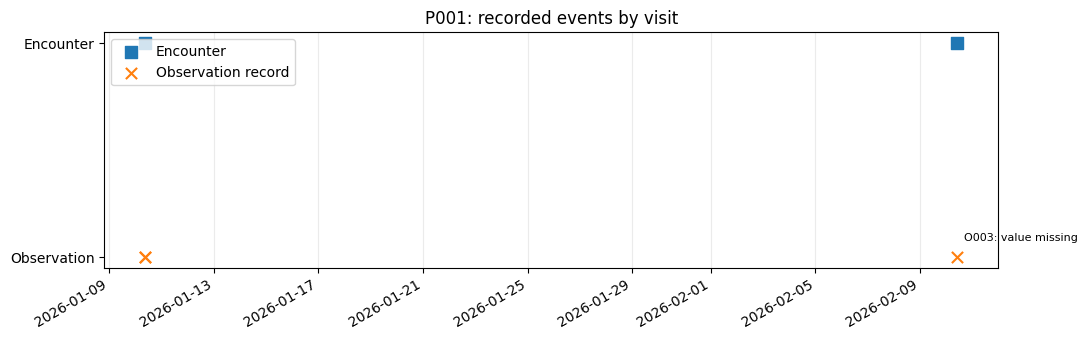

In [12]:
p1_encounters = encounters.loc[encounters["patient_id"].eq("P001")].copy()
p1_obs = linked.loc[linked["patient_id"].eq("P001")].copy()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.scatter(
    p1_encounters["start"].dt.tz_convert("Asia/Kolkata"),
    [1] * len(p1_encounters), label="Encounter", marker="s", s=65
)
ax.scatter(
    p1_obs["effective_time"].dt.tz_convert("Asia/Kolkata"),
    [0] * len(p1_obs), label="Observation record", marker="x", s=65
)
for row in p1_obs.itertuples():
    if pd.isna(row.value):
        ax.annotate(
            f"{row.observation_id}: value missing",
            (row.effective_time.tz_convert("Asia/Kolkata"), 0),
            xytext=(5, 12), textcoords="offset points", fontsize=8
        )
ax.set_yticks([0, 1], ["Observation", "Encounter"])
ax.set_title("P001: recorded events by visit")
ax.legend(loc="upper left")
ax.grid(axis="x", alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

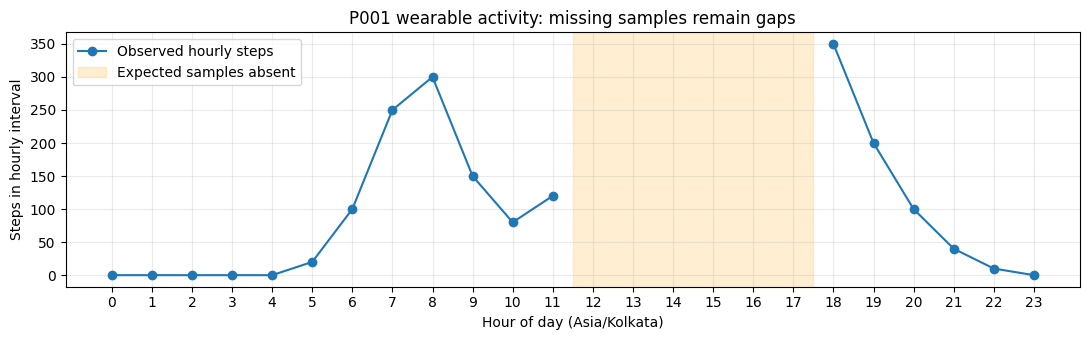

Missing expected hourly samples: 6
Missing hours: ['12:00', '13:00', '14:00', '15:00', '16:00', '17:00']


In [13]:
expected = pd.date_range("2026-01-10", periods=24, freq="h", tz="Asia/Kolkata")
wearable_local = wearable.set_index("time")["steps"].tz_convert("Asia/Kolkata")
series = wearable_local.reindex(expected)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(series.index.hour, series.values, marker="o", label="Observed hourly steps")
ax.axvspan(11.5, 17.5, alpha=0.18, color="orange", label="Expected samples absent")
ax.set(
    xlabel="Hour of day (Asia/Kolkata)",
    ylabel="Steps in hourly interval",
    title="P001 wearable activity: missing samples remain gaps"
)
ax.set_xticks(range(24))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

missing_hours = series[series.isna()].index
print("Missing expected hourly samples:", int(series.isna().sum()))
print("Missing hours:", [timestamp.strftime("%H:%M") for timestamp in missing_hours])
assert series.isna().sum() == 6

### Student response — plot interpretation

The orange region marks the six hourly timestamps for which the generator says samples were expected but no wearable rows were supplied. These are missing observations, not measured values of zero. Replacing them with zero would create a false conclusion that P001 recorded no steps during those hours and would distort activity summaries, trends, and any model features derived from the series.

The timeline includes `O003` because an observation record exists for it: it has an observation identifier, encounter reference, code, unit, and effective timestamp. Its numeric heart-rate value is missing, but the event itself was recorded. The timeline is showing recorded events, not only non-missing numeric results.

## 7. Final reflection (150–250 words)

Flattening the FHIR resources into a table makes selected fields easier to compare, but it loses resource structure and context. For example, the flattened rows do not preserve the complete resource hierarchy, Bundle entry `fullUrl`, Observation status, the full coding array, all reference metadata, or other optional FHIR elements. The extraction also keeps only selected fields and therefore cannot represent every feature of the original resources.

Before training a model, at least three limitations matter. First, the data are synthetic and extremely small, so they cannot support reliable estimates of real clinical patterns or model performance. Second, data quality problems—including missing measurement values, mixed units, duplicated exports, and gaps in wearable sampling—could create misleading features if not handled explicitly. Third, the sources are incomplete and selectively linked: the FHIR Bundle contains only two observations, notes are free text, and patients without observations can disappear from an observation-level table. The cohort is also based on record availability rather than disease status.

If prediction is made at encounter start, a measurement recorded ten minutes after the encounter begins would not yet be available and must not be used as an input. A real system therefore needs a separate **result-availability timestamp** (for example, when the result was finalized and became accessible to the prediction system), in addition to the clinical event/effective timestamp. This fixture supplies `effective_time` but does not supply a result-availability timestamp, so that availability time cannot be recovered from these files.

## 8. Final validation checks

These assertions check the main expected results for this synthetic fixture. Passing them supports reproducibility of the notebook's transformations; it does not establish clinical validity or guarantee a particular grade.

In [14]:
# Inventory and data dictionary
assert len(data_dictionary) == 14
assert data_dictionary["file"].nunique() >= 3

# Quality and temperature conversion
assert observations.duplicated().sum() == 1
assert len(clean_obs) == 6
assert clean_obs["observation_id"].is_unique
assert temperature_copy["unit"].tolist() == ["Cel", "[degF]"]
assert all(abs(temperature_copy["value_celsius"] - 37.0) < 1e-9)

# Linkage and note consistency
assert len(linked) == 6
assert linked["patient_id"].nunique() == 3
assert matched_notes["patient_id_encounter"].eq(matched_notes["patient_id_note"]).all()
assert len(bad_join.loc[bad_join["patient_id"].eq("P001")]) == 4

# Cohort
assert cohort[["patient_id", "encounter_count"]].to_dict("records") == [
    {"patient_id": "P001", "encounter_count": 2}
]

# FHIR and wearable
assert len(fhir_frame) == 2
assert len(comparison) == 2
assert int(series.isna().sum()) == 6

print("All notebook validation assertions passed.")

All notebook validation assertions passed.


# Final Written Responses – Data Ecosystem Lab 1
**Student: Jasneet Kaur**

## 1. Data Inventory and Dictionary

The dataset contains five main files: patients, encounters, observations, notes and wearable data.

- `patients.csv`: Each row represents one patient. The primary identifier is patient_id. It contains demographic information such as birth year.
- `encounters.csv`: Each row represents one healthcare encounter. encounter_id uniquely identifies a visit, while patient_id connects the visit to a patient.
- `observations.csv`: Each row represents a recorded clinical measurement. observation_id identifies the observation, while encounter_id links it to the relevant visit.
- `notes.csv`: Each row represents a clinical note. note_id identifies the note, and patient_id and encounter_id connect it to the patient and visit.
- `wearable.csv`: Each row represents a wearable-device measurement at a particular time. Patient_id and timestamp together identify the sample.

These files contain structured data as well as unstructured information. In particular, clinical notes contain free-text descriptions that cannot be interpreted reliably using simple structured-field matching.

The data dictionary documents the meaning, representation, units, key roles and missingness of the important fields.

## 2. Data Quality Issues

Four important data-quality problems were identified.

**1. Duplicate records**

Observation O001 appears twice with identical values, encounter, measurement code, unit and timestamp. Since the complete rows are identical, one copy can reasonably be removed as a duplicated export record. However, repeated identifiers alone do not justify deletion. If two records with the same ID contain different values or timestamps, they must be investigated before deciding whether either record should be removed.

**2. Missing values**

Observation O003 has a recorded observation identifier and timestamp, but its numeric measurement value is missing. This does not mean that the measured value was zero. Replacing it with zero would introduce false clinical information.

**3. Mixed measurement units**

Temperature values are recorded in Celsius and Fahrenheit. Direct comparison would be misleading because the units differ. I converted the Fahrenheit value into Celsius in a separate copy while preserving the original value and unit for traceability.

**4. Keyword-matching limitations**

Simple keyword matching can incorrectly identify clinical conditions. For example, the phrase "No history of diabetes" contains the word diabetes but explicitly negates a personal history. Similarly, "Family history of diabetes" refers to a family member rather than confirming that the patient has diabetes.

Therefore, clinical text interpretation must consider negation, subject, temporality and uncertainty.

## 3. Record Linkage and Note Joining

The observation data were linked to encounters using encounter_id, and encounters were linked to patients using patient_id.

Each row of the resulting linked dataset represents one observation associated with a particular encounter and patient.

The join was validated to ensure that each observation matched the correct encounter and patient. The resulting dataset contains six observations belonging to three patients.

P004 does not appear in the observation-linked dataset because this patient has an encounter but no observation record. To retain such patients, a left join should be used starting from the patient or encounter table. This preserves records even when corresponding observations are unavailable.

The note join uses encounter_id because notes must be associated with the correct visit. Joining only on patient_id can incorrectly associate notes with multiple encounters belonging to the same patient. For P001, this produces four combinations instead of the two correct note-to-encounter relationships.

A patient-consistency check was also performed to ensure that the patient referenced by each note matches the patient associated with its encounter.

## 4. Cohort Definition

The cohort was defined using a half-open time interval:

[1 January 2026, 1 March 2026)

Patients were required to have at least two distinct encounters within this interval.

The resulting cohort contains P001, with two qualifying encounters.

P003 has one encounter on 20 January 2026 and another on 1 March 2026. The second encounter falls exactly on the exclusive end boundary and is therefore excluded. Consequently, P003 has only one eligible encounter and does not satisfy the cohort requirement.

Distinct encounter identifiers were counted instead of observation rows because multiple observations may belong to one encounter.

## 5. FHIR Comparison

The FHIR Bundle represents selected clinical information using structured resources.

The following paths were examined:

- Patient reference: Observation.subject.reference
- Encounter reference: Observation.encounter.reference
- Coding system: Observation.code.coding[].system
- Measurement code: Observation.code.coding[].code
- Quantity value: Observation.valueQuantity.value
- Unit display: Observation.valueQuantity.unit
- Unit coding system: Observation.valueQuantity.system
- Coded unit: Observation.valueQuantity.code
- Effective timestamp: Observation.effectiveDateTime

The coding system identifies the terminology used to describe the measurement. The unit system and coded unit provide standardized machine-readable information, whereas the display label is intended for human readability.

The FHIR Bundle contains fewer observations than the CSV dataset because it represents only a selected subset of the available records.

Agreement between the CSV and FHIR records demonstrates consistency for the fields compared. However, agreement does not prove that the dataset is complete, that all measurements are accurate, or that the information is clinically valid.

## 6. Plot Interpretation

The patient timeline displays encounters and observation events in chronological order. It helps show how measurements relate to individual visits.

O003 appears on the timeline even though its numeric value is missing. This is because the observation event itself was recorded, including its identifier and timestamp. Missing measurement results do not mean that the event never occurred.

The wearable activity plot highlights the orange region where expected hourly samples are absent. These gaps represent missing data rather than zero activity.

Treating missing wearable samples as zero would incorrectly suggest that the patient recorded no steps during those periods. This could distort activity summaries and introduce misleading information into a predictive model.

## 7. Reflection

Working with multiple healthcare data sources demonstrates that combining records is not simply a matter of joining tables. Flattening FHIR resources into a tabular structure makes analysis easier but can remove important context, including resource relationships, coding details, status information and other metadata.

There are several limitations to consider before using these data for model training. First, the dataset is synthetic and very small, so its patterns cannot be assumed to represent real patients. Second, missing measurements, duplicated exports, mixed units and wearable sampling gaps can introduce errors into analysis and model features. Third, the FHIR Bundle contains only selected observations, while clinical notes contain unstructured text that may require additional processing and validation. The cohort also reflects record availability rather than confirmed disease status.

An additional concern is the difference between effective time and result-availability time. A measurement may have an effective timestamp indicating when it was taken, but the result might only become available later. For a prediction made at encounter start, information that becomes available after that prediction time must not be used as an input. A separate result-availability timestamp is therefore necessary to prevent temporal data leakage. This dataset provides effective timestamps but does not provide an explicit result-availability timestamp, so the actual time when results became accessible cannot be established.

Overall, reliable healthcare modelling requires careful data validation, correct record linkage, standardized units, preservation of missingness and awareness of the clinical context behind each record.
